
Các bước:
1. Import thư viện
2. Đọc dữ liệu từ `data/split.csv`
3. Xây dựng mô hình
4. Huấn luyện
5. Vẽ biểu đồ học
6. Đánh giá trên tập test
7. Lưu kết quả

## Bước 1 – Import thư viện

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Tìm thư mục gốc của dự án (nơi có config.py), không phụ thuộc thư mục chạy notebook.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục dự án chứa config.py")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import config

ROOT = PROJECT_ROOT
RESULTS_DIR = ROOT / "results" / "custom_cnn"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
(ROOT / "models").mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("split.csv exists:", config.SPLIT_CSV_PATH.exists())
print("CPUs available:", tf.config.list_physical_devices("CPU"))

I0000 00:00:1791613291.341896    4948 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791613291.396380    4948 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791613292.478911    4948 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
PROJECT_ROOT: /tmp/claude-1000/-home-minhquang-Fire-and-smoke-detection-using-D-Fire/1462ddb6-20b0-4166-a199-2ce4f68e9ba7/scratchpad/wt_friend
split.csv exists: True
CPUs available: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## Bước 2 – Đọc dữ liệu
`split.csv` chứa đường dẫn tới 4800 ảnh đã resize 224x224 và cột `split` (train/val/test).

In [2]:
df = pd.read_csv(config.SPLIT_CSV_PATH)

print("Số hàng:", len(df))
print(df.groupby(["split", "label"]).size().unstack())

Số hàng: 4800
label  fire  nofire  smoke  smokefire
split                                
test    200     200    200        200
train   800     800    800        800
val     200     200    200        200


In [3]:
# Đọc 1 ảnh từ đường dẫn, chuẩn hoá về [0, 1]
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.cast(img, tf.float32) / 255.0
    img.set_shape([224, 224, 3])
    return img, label


# Tạo dataset cho từng tập (train / val / test)
def make_dataset(split_name, shuffle=False):
    part = df[df["split"] == split_name].reset_index(drop=True)
    paths = [str(ROOT / p) for p in part["processed_filepath"]]
    labels = part["class_index"].astype(int).tolist()

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=config.RANDOM_SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(32).prefetch(tf.data.AUTOTUNE)
    return ds, part


train_ds, train_df = make_dataset("train", shuffle=True)
val_ds, val_df = make_dataset("val")
test_ds, test_df = make_dataset("test")

print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))

W0000 00:00:1791613294.076226    4948 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1791613294.076573    4948 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3618 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Train: 3200 | Val: 800 | Test: 800


## Bước 3 – Xây dựng mô hình

CNN chỉ xếp Conv2D liên tiếp thì khó học khi mạng sâu (gradient biến mất) và không biết kênh nào quan trọng. Nên mình dùng:
- **Residual (đường tắt)**: cộng input vào output để gradient đi thẳng được.
- **SE block**: mạng tự học trọng số cho từng kênh (lửa là kênh cam/đỏ, khói là vùng mờ).
- **Global Average Pooling**: thay Flatten để ít tham số hơn, đỡ overfit.

In [4]:
# Khối residual có kèm SE
def res_block(x, filters, stride=1):
    shortcut = x

    # 2 lớp conv
    x = layers.Conv2D(filters, 3, strides=stride, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)

    # SE: mỗi kênh gom thành 1 số, học trọng số 0-1 rồi nhân lại
    se = layers.GlobalAveragePooling2D()(x)
    se = layers.Dense(filters // 16, activation="relu")(se)
    se = layers.Dense(filters, activation="sigmoid")(se)
    se = layers.Reshape((1, 1, filters))(se)
    x = layers.Multiply()([x, se])

    # nếu kích thước đổi thì shortcut cũng phải đổi theo mới cộng được
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride)(shortcut)

    x = layers.Add()([x, shortcut])
    return layers.Activation("relu")(x)

In [5]:
inputs = layers.Input(shape=(224, 224, 3))

# conv đầu, stride 2 giảm ảnh còn 112x112
x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(inputs)

x = res_block(x, 64)                # 112x112
x = res_block(x, 128, stride=2)     # 56x56
x = res_block(x, 128)
x = res_block(x, 256, stride=2)     # 28x28
x = res_block(x, 256)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
outputs = layers.Dense(len(config.CLASS_NAMES), activation="softmax")(x)

model = models.Model(inputs, outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │     18,496 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     36,928 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4)         │        260 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │        320 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 64)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │      2,112 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 112, 112,  │          0 │ multiply[0][0],   │
│                     │ 64)               │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 112, 112,  │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     73,856 │ activation_1[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ batch_normalizat

 Total params: 2,743,736 (10.47 MB)

 Trainable params: 2,740,408 (10.45 MB)

 Non-trainable params: 3,328 (13.00 KB)

## Bước 4 – Compile và huấn luyện
Chạy tối đa 50 epoch, `EarlyStopping` sẽ dừng sớm nếu val_loss không giảm nữa và lấy lại trọng số tốt nhất.

In [6]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              metrics=["accuracy"])

callbacks = [
    # dừng nếu val_loss không giảm sau 10 epoch
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                     restore_best_weights=True),
    # giảm learning rate một nửa nếu val_loss đứng yên 4 epoch
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                         patience=4, min_lr=1e-6),
]

In [7]:
H = model.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=callbacks)

Epoch 1/50


/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


I0000 00:00:1791613301.513659    5005 service.cc:153] XLA service 0x73d9ec158a50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791613301.513686    5005 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.20.0)
I0000 00:00:1791613301.679052    5005 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


I0000 00:00:1791613302.910184    5005 cuda_dnn.cc:461] Loaded cuDNN version 92000
I0000 00:00:1791613303.050647    5005 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_13402__.112


I0000 00:00:1791613315.005626    5005 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


...

 97/100 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.9887 - loss: 0.0436

 98/100 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - accuracy: 0.9888 - loss: 0.0435

 99/100 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - accuracy: 0.9890 - loss: 0.0433

100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - accuracy: 0.9887 - loss: 0.0433

100/100 ━━━━━━━━━━━━━━━━━━━━ 23s 232ms/step - accuracy: 0.9887 - loss: 0.0433 - val_accuracy: 0.9600 - val_loss: 0.1468 - learning_rate: 6.2500e-05


In [8]:
model.save(ROOT / "models" / "custom_cnn.keras")

## Bước 5 – Biểu đồ quá trình học

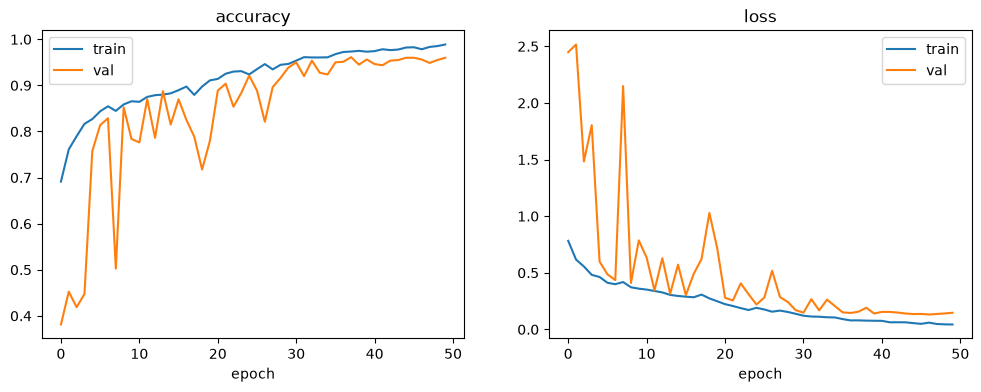

In [9]:
plt.figure(figsize=(12, 4))
for i, name in enumerate(["accuracy", "loss"]):
    plt.subplot(1, 2, i + 1)
    plt.plot(H.history[name], label="train")
    plt.plot(H.history["val_" + name], label="val")
    plt.title(name)
    plt.xlabel("epoch")
    plt.legend()

plt.savefig(RESULTS_DIR / "learning_curves.png", dpi=150)
plt.show()

## Bước 6 – Đánh giá trên tập test

In [10]:
# model đã được EarlyStopping khôi phục về trọng số tốt nhất nên dùng luôn
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)
y_true = test_df["class_index"].astype(int).values

print("Đoán đúng:", (y_pred == y_true).sum(), "/", len(y_true))
print(classification_report(y_true, y_pred, target_names=config.CLASS_NAMES, digits=4))

 1/25 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step

 2/25 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step

 3/25 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step

 4/25 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step

 5/25 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step

...

24/25 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step

25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step


Đoán đúng: 611 / 800


              precision    recall  f1-score   support

        fire     0.8873    0.6300    0.7368       200
      nofire     0.9135    0.9500    0.9314       200
       smoke     0.7701    0.7200    0.7442       200
   smokefire     0.5741    0.7550    0.6523       200

    accuracy                         0.7638       800
   macro avg     0.7862    0.7637    0.7662       800
weighted avg     0.7862    0.7638    0.7662       800



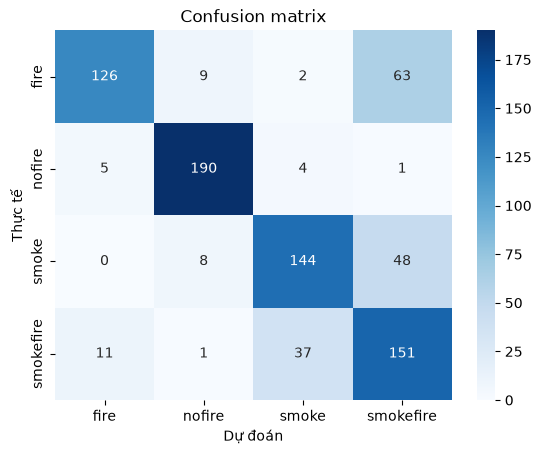

In [11]:
cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=config.CLASS_NAMES, yticklabels=config.CLASS_NAMES)
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.title("Confusion matrix")
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## Bước 7 – Lưu kết quả

In [12]:
metrics = {
    "model_name": "Custom CNN (Residual + SE)",
    "test_accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
    "test_macro_f1": round(float(f1_score(y_true, y_pred, average="macro")), 4),
    "total_parameters": int(model.count_params()),
    "epochs_trained": len(H.history["loss"]),
}

with open(RESULTS_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print(metrics)

{'model_name': 'Custom CNN (Residual + SE)', 'test_accuracy': 0.7638, 'test_macro_f1': 0.7662, 'total_parameters': 2743736, 'epochs_trained': 50}
